# Credit Risk Scoring — German Credit Dataset (UCI)

**Author:** RAHHAL Fatima Zahrae · [GitHub](https://github.com/rahhalfatimazahrae) · [LinkedIn](https://www.linkedin.com/in/fatima-zahrae-rahhal-88b459300/)

---

**Goal:** predict whether a loan applicant is a *good* or *bad* credit risk, and choose a decision rule that minimises the **business cost** of mistakes.

**Data:** UCI *Statlog (German Credit Data)* — 1,000 applicants, 20 features (7 numerical, 13 categorical), 30 % bad risks.

**Key result:** tuning the decision threshold to the 5:1 cost matrix (threshold 0.33) cut the test-set cost from **150 to 94 (−37 %)** and raised the share of bad clients caught from **58 % to 90 %**.

**Contents**
1. Setup & data loading
2. Data overview & quality checks
3. Exploratory data analysis
4. Preprocessing & train/test split
5. Model comparison (cross-validation)
6. Final evaluation on the test set
7. Cost-sensitive decision threshold
8. Interpretability
9. Conclusions & limitations

## 1. Setup & data loading
The raw file has no header and uses coded values (`A11`, `A34`…). We attach column names and decode categories into readable labels.

In [18]:
import os
os.environ["OMP_NUM_THREADS"] = "2"
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score,
                             confusion_matrix, roc_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")

# Works whether the notebook sits next to the data file or inside notebooks/ (repo layout)
from pathlib import Path
DATA_PATH = next(p for p in (Path("german.data"), Path("../data/german.data"), Path("data/german.data")) if p.exists())
IMG = "../images/" if Path("../data").exists() else "images/"
import os; os.makedirs(IMG, exist_ok=True)

In [2]:
columns = ["checking_account","duration","credit_history","purpose","credit_amount","savings",
           "employment","installment_rate","personal_status","other_debtors","residence_since","property",
           "age","other_installment_plans","housing","existing_credits","job","num_dependents",
           "telephone","foreign_worker","credit_risk"]

df = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=columns)

# Decode categorical codes into readable labels
decode = {'checking_account': {'A11': '< 0 DM', 'A12': '0-200 DM', 'A13': '>= 200 DM / salary', 'A14': 'no checking account'}, 'credit_history': {'A30': 'no credits / all paid', 'A31': 'all paid at this bank', 'A32': 'existing paid duly', 'A33': 'past delay', 'A34': 'critical / other credits'}, 'purpose': {'A40': 'car (new)', 'A41': 'car (used)', 'A42': 'furniture', 'A43': 'radio/TV', 'A44': 'appliances', 'A45': 'repairs', 'A46': 'education', 'A47': 'vacation', 'A48': 'retraining', 'A49': 'business', 'A410': 'other'}, 'savings': {'A61': '< 100 DM', 'A62': '100-500 DM', 'A63': '500-1000 DM', 'A64': '>= 1000 DM', 'A65': 'unknown / none'}, 'employment': {'A71': 'unemployed', 'A72': '< 1 yr', 'A73': '1-4 yrs', 'A74': '4-7 yrs', 'A75': '>= 7 yrs'}, 'personal_status': {'A91': 'male div/sep', 'A92': 'female div/sep/married', 'A93': 'male single', 'A94': 'male married/widowed', 'A95': 'female single'}, 'other_debtors': {'A101': 'none', 'A102': 'co-applicant', 'A103': 'guarantor'}, 'property': {'A121': 'real estate', 'A122': 'savings/insurance', 'A123': 'car/other', 'A124': 'unknown / none'}, 'other_installment_plans': {'A141': 'bank', 'A142': 'stores', 'A143': 'none'}, 'housing': {'A151': 'rent', 'A152': 'own', 'A153': 'free'}, 'job': {'A171': 'unemployed/unskilled non-res.', 'A172': 'unskilled resident', 'A173': 'skilled', 'A174': 'management/highly qualified'}, 'telephone': {'A191': 'none', 'A192': 'yes'}, 'foreign_worker': {'A201': 'yes', 'A202': 'no'}}
for col, mapping in decode.items():
    df[col] = df[col].map(mapping)

# Target: 1 = bad risk (positive class), 0 = good risk
df["credit_risk"] = df["credit_risk"].map({1: 0, 2: 1})

print(df.shape)
df.head()

(1000, 21)


,checking_account,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,credit_risk
0,< 0 DM,6,critical / other credits,radio/TV,1169,unknown / none,>= 7 yrs,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,0
1,0-200 DM,48,existing paid duly,radio/TV,5951,< 100 DM,1-4 yrs,2,female div/sep/married,none,...,real estate,22,none,own,1,skilled,1,none,yes,1
2,no checking account,12,critical / other credits,education,2096,< 100 DM,4-7 yrs,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,0
3,< 0 DM,42,existing paid duly,furniture,7882,< 100 DM,4-7 yrs,2,male single,guarantor,...,savings/insurance,45,none,free,1,skilled,2,none,yes,0
4,< 0 DM,24,past delay,car (new),4870,< 100 DM,1-4 yrs,3,male single,none,...,unknown / none,53,none,free,2,skilled,2,none,yes,1


## 2. Data overview & quality checks

In [3]:
print("Rows / columns:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicated rows:", int(df.duplicated().sum()))
bad_rate = df["credit_risk"].mean()
print(f"Bad-risk rate: {bad_rate:.1%}  |  Good-risk rate: {1-bad_rate:.1%}")
df.describe().T

Rows / columns: (1000, 21)
Missing values: 0
Duplicated rows: 0
Bad-risk rate: 30.0%  |  Good-risk rate: 70.0%


,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
num_dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0
credit_risk,1000.0,0.300,0.458487,0.0,0.0,0.0,1.00,1.0


The dataset is clean (no missing values, no duplicates) but **imbalanced**: about 30 % bad risks. Accuracy alone would therefore be misleading — a model that approves everybody already scores ~70 %.

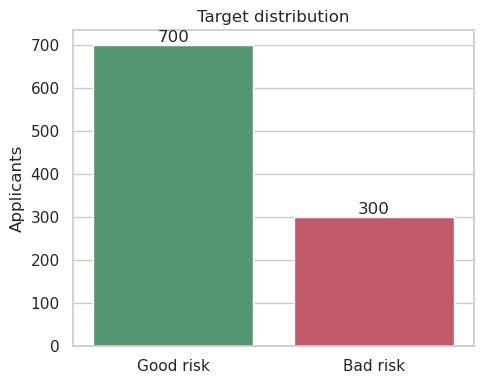

In [4]:
fig, ax = plt.subplots(figsize=(5,4))
sns.countplot(data=df, x="credit_risk", ax=ax, palette=["#4C9F70","#D1495B"])
ax.set_xticklabels(["Good risk","Bad risk"])
ax.set_xlabel(""); ax.set_ylabel("Applicants")
ax.set_title("Target distribution")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig(IMG+"01_target_en.png", dpi=150); plt.show()

## 3. Exploratory data analysis
### 3.1 Numerical variables vs. risk

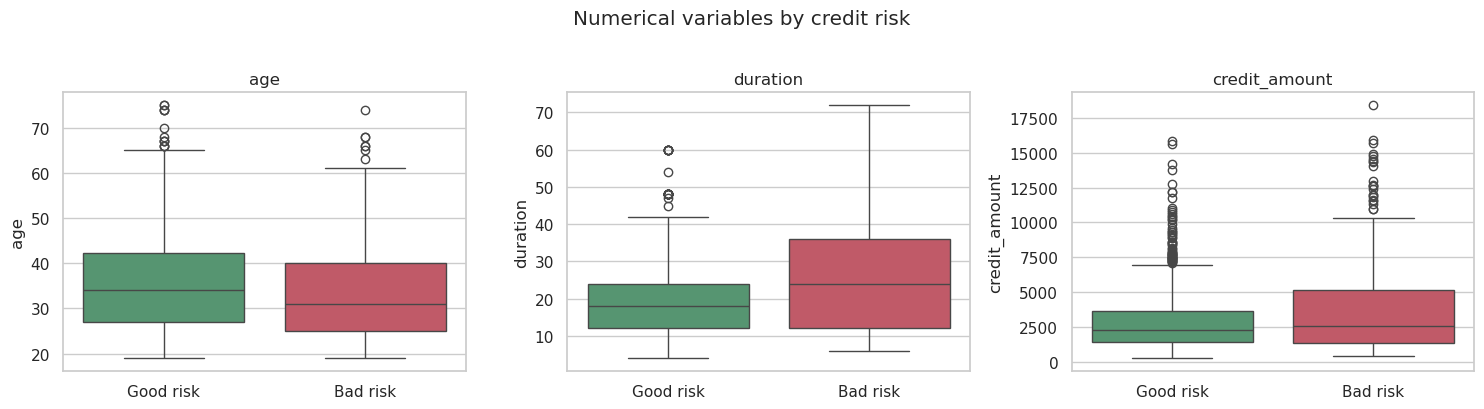

,age,duration,credit_amount
credit_risk,,,
0,34.0,18.0,2244.0
1,31.0,24.0,2574.5


In [5]:
num_cols = ["age","duration","credit_amount"]
labels = {0:"Good risk", 1:"Bad risk"}
d = df.assign(risk=df["credit_risk"].map(labels))
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=d, x="risk", y=c, order=["Good risk","Bad risk"], palette=["#4C9F70","#D1495B"], ax=ax)
    ax.set_xlabel(""); ax.set_title(c)
plt.suptitle("Numerical variables by credit risk", y=1.02); plt.tight_layout()
plt.savefig(IMG+"02_numeric_en.png", dpi=150, bbox_inches="tight"); plt.show()
df.groupby("credit_risk")[num_cols].median()

Bad risks tend to ask for **larger amounts over longer durations** and are slightly **younger**.

### 3.2 Categorical variables — default rate per category

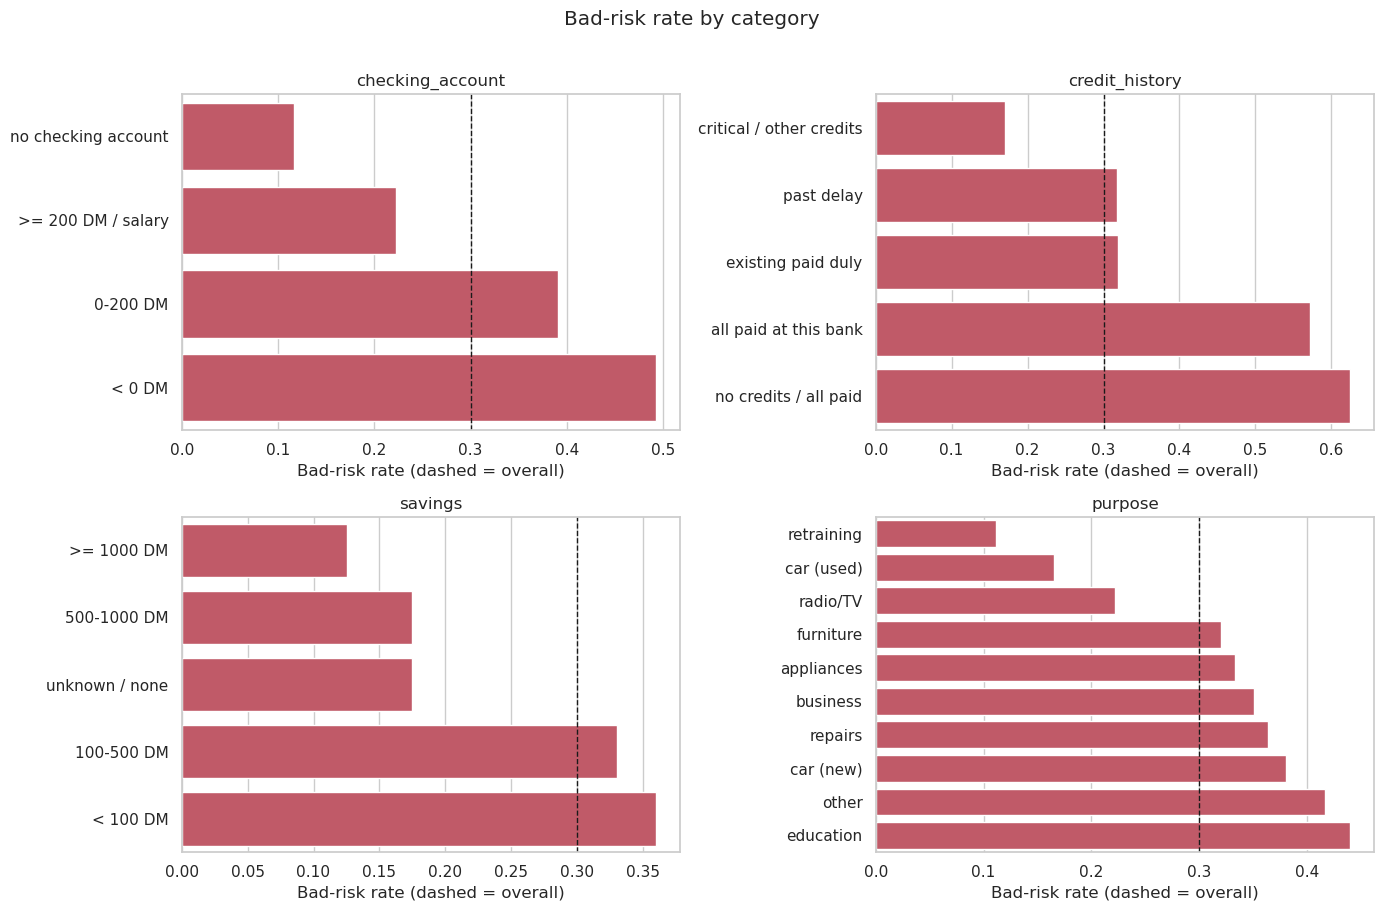

In [6]:
cats = ["checking_account","credit_history","savings","purpose"]
fig, axes = plt.subplots(2, 2, figsize=(14,9))
for ax, c in zip(axes.ravel(), cats):
    rate = df.groupby(c)["credit_risk"].mean().sort_values()
    sns.barplot(x=rate.values, y=rate.index, color="#D1495B", ax=ax)
    ax.axvline(df["credit_risk"].mean(), color="k", ls="--", lw=1)
    ax.set_xlabel("Bad-risk rate (dashed = overall)"); ax.set_ylabel(""); ax.set_title(c)
plt.suptitle("Bad-risk rate by category", y=1.01); plt.tight_layout()
plt.savefig(IMG+"03_categorical_en.png", dpi=150, bbox_inches="tight"); plt.show()

The **checking account status** is the strongest signal: applicants with a negative balance default far more often than those with no checking account. Low savings also raise risk. Counter-intuitively, a *critical* credit history shows the **lowest** default rate (17 %) while “no credits / all paid” shows the highest (57-62 %): a known quirk of this dataset (customers with a long banking history are probably better screened), not a causal rule.

### 3.3 Correlations (numerical features)

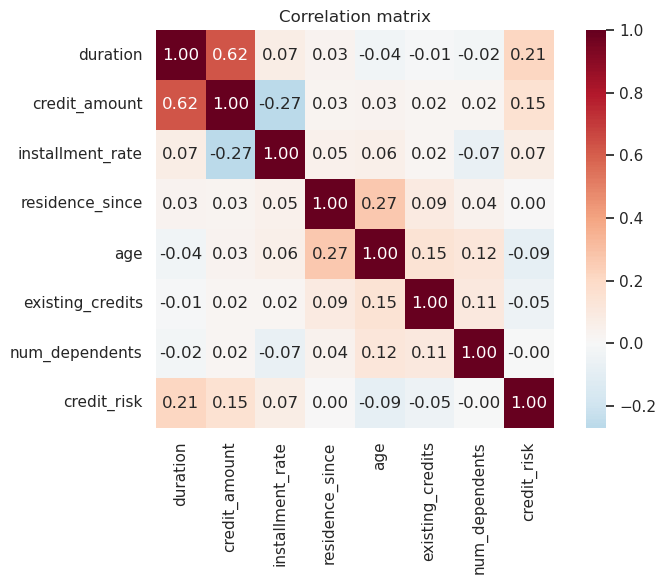

In [7]:
num_all = df.select_dtypes("number").columns
plt.figure(figsize=(8,6))
sns.heatmap(df[num_all].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Correlation matrix"); plt.tight_layout()
plt.savefig(IMG+"04_corr_en.png", dpi=150); plt.show()

`duration` and `credit_amount` are strongly correlated (≈ 0.62), which is expected: larger loans run longer. No pair is correlated enough to require dropping features.

## 4. Preprocessing & train/test split
The split is **stratified** so both sets keep the 70/30 class ratio. All preprocessing lives inside a `Pipeline`, so scaling and encoding are fit on training folds only (**no data leakage**).

In [8]:
X = df.drop(columns="credit_risk"); y = df["credit_risk"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)

num_features = X.select_dtypes("number").columns.tolist()
cat_features = X.select_dtypes(exclude="number").columns.tolist()

# Fixed category order (original code order) -> identical results whatever the label language
cat_order = [list(decode[c].values()) for c in cat_features]
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(categories=cat_order, sparse_output=False), cat_features),
])
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Bad rate train/test:", round(y_train.mean(),3), round(y_test.mean(),3))

Train: (800, 20) | Test: (200, 20)
Bad rate train/test: 0.3 0.3


## 5. Model comparison (5-fold stratified cross-validation)
We compare four models on the **training set only**. Metrics: **ROC-AUC** (ranking quality), **PR-AUC** (robust to imbalance) and **Recall of bad risks** (how many defaulters we catch).

In [19]:
models = {
    "Logistic Regression":            LogisticRegression(max_iter=2000),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest (balanced)":       RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced", random_state=SEED, n_jobs=1),
    "Gradient Boosting":              HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED),
}
pipes = {n: Pipeline([("prep", preprocessor), ("clf", m)]) for n, m in models.items()}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"roc_auc":"roc_auc", "pr_auc":"average_precision", "recall_bad":"recall"}

rows = []
for name, pipe in pipes.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"model": name,
                 "ROC-AUC": r["test_roc_auc"].mean(), "ROC-AUC (std)": r["test_roc_auc"].std(),
                 "PR-AUC": r["test_pr_auc"].mean(), "Recall (bad)": r["test_recall_bad"].mean()})
cv_results = pd.DataFrame(rows).set_index("model").round(3).sort_values("ROC-AUC", ascending=False)
cv_results

,ROC-AUC,ROC-AUC (std),PR-AUC,Recall (bad)
model,,,,
Random Forest (balanced),0.797,0.043,0.634,0.562
Gradient Boosting,0.789,0.044,0.606,0.446
Logistic Regression,0.771,0.053,0.594,0.433
Logistic Regression (balanced),0.769,0.053,0.589,0.671


In [10]:
best_name = cv_results.index[0]
print("Best model by CV ROC-AUC:", best_name)

Best model by CV ROC-AUC: Random Forest (balanced)


## 6. Final evaluation on the hold-out test set
Each model is refit on the full training set and evaluated **once** on the untouched test set (default threshold 0.5).

In [11]:
fitted, proba, rows = {}, {}, []
for name, pipe in pipes.items():
    pipe.fit(X_train, y_train); fitted[name] = pipe
    p = pipe.predict_proba(X_test)[:,1]; proba[name] = p
    pred = (p >= 0.5).astype(int)
    rows.append({"model": name, "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
                 "Recall (bad)": recall_score(y_test, pred), "Precision (bad)": precision_score(y_test, pred)})
test_results = pd.DataFrame(rows).set_index("model").round(3).sort_values("ROC-AUC", ascending=False)
test_results

,ROC-AUC,PR-AUC,Recall (bad),Precision (bad)
model,,,,
Logistic Regression (balanced),0.806,0.633,0.800,0.558
Logistic Regression,0.804,0.635,0.533,0.667
Random Forest (balanced),0.803,0.653,0.583,0.583
Gradient Boosting,0.784,0.623,0.483,0.604


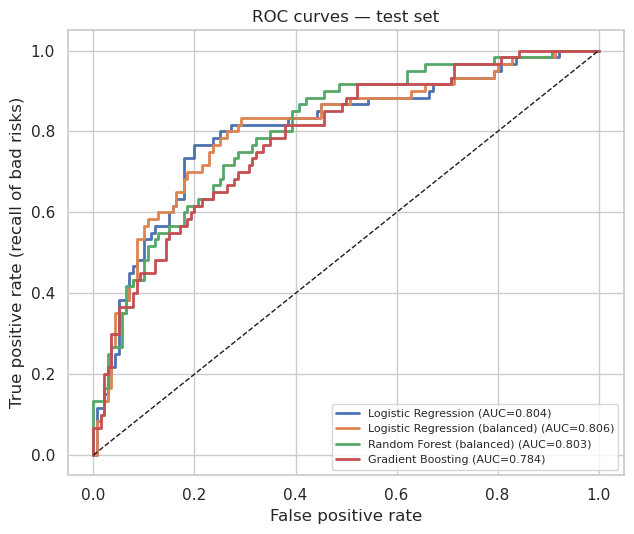

In [12]:
plt.figure(figsize=(6.5,5.5))
for name, p in proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC={roc_auc_score(y_test,p):.3f})")
plt.plot([0,1],[0,1],"k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall of bad risks)"); plt.title("ROC curves — test set")
plt.legend(loc="lower right", fontsize=8); plt.tight_layout()
plt.savefig(IMG+"05_roc_en.png", dpi=150); plt.show()

## 7. Cost-sensitive decision threshold
In the original dataset documentation, the **cost matrix is asymmetric**:

| | Predicted good | Predicted bad |
|---|---|---|
| **Actually good** | 0 | 1 (lost business) |
| **Actually bad** | **5** (default loss) | 0 |

Approving a defaulter costs **5×** more than rejecting a good client, so the default 0.5 threshold is not optimal. If probabilities were perfectly calibrated, the optimal rule would be to flag an applicant as bad when p > 1/(1+5) ≈ **0.17**.

To avoid leaking the test set, the threshold is **chosen on out-of-fold predictions of the training set**, then applied once to the test set.

In [13]:
COST_FN, COST_FP = 5, 1   # FN: bad client approved | FP: good client rejected

def total_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return COST_FN*fn + COST_FP*fp

best_pipe = pipes[best_name]
oof = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba")[:,1]

thresholds = np.linspace(0.05, 0.95, 91)
oof_costs = [total_cost(y_train, (oof >= th).astype(int)) for th in thresholds]
best_th = float(thresholds[int(np.argmin(oof_costs))])
print("Threshold selected on training OOF predictions:", round(best_th, 2))

Threshold selected on training OOF predictions: 0.33


In [14]:
p_test = proba[best_name]
strategies = {
    "Approve everybody": np.zeros(len(y_test), dtype=int),
    "Reject everybody": np.ones(len(y_test), dtype=int),
    "Model @ threshold 0.5": (p_test >= 0.5).astype(int),
    f"Model @ optimised threshold ({best_th:.2f})": (p_test >= best_th).astype(int),
}
res = []
for k, pred in strategies.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    res.append({"strategy": k, "total cost": COST_FN*fn + COST_FP*fp, "Recall (bad)": round(tp/(tp+fn),3),
                "False-positive rate": round(fp/(fp+tn),3)})
cost_table = pd.DataFrame(res).set_index("strategy")
cost_table

,total cost,Recall (bad),False-positive rate
strategy,,,
Approve everybody,300,0.000,0.000
Reject everybody,140,1.000,1.000
Model @ threshold 0.5,150,0.583,0.179
Model @ optimised threshold (0.33),94,0.900,0.457


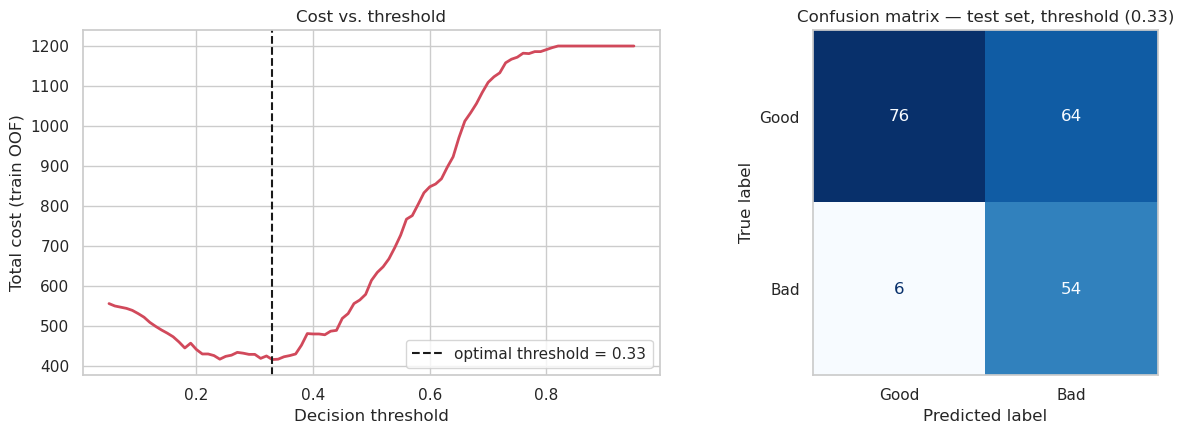

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
axes[0].plot(thresholds, oof_costs, color="#D1495B", lw=2)
axes[0].axvline(best_th, color="k", ls="--", label=f"optimal threshold = {best_th:.2f}")
axes[0].set_xlabel("Decision threshold"); axes[0].set_ylabel("Total cost (train OOF)"); axes[0].set_title("Cost vs. threshold"); axes[0].legend()

ConfusionMatrixDisplay.from_predictions(y_test, (p_test >= best_th).astype(int), ax=axes[1],
    display_labels=["Good","Bad"], cmap="Blues", colorbar=False)
axes[1].set_title("Confusion matrix — test set, threshold " + f"({best_th:.2f})"); axes[1].grid(False)
plt.tight_layout(); plt.savefig(IMG+"06_threshold_en.png", dpi=150); plt.show()

## 8. Interpretability
### 8.1 Logistic regression odds ratios
Odds ratio > 1 means the feature **increases** the odds of being a bad risk. Numerical variables are standardised, so their odds ratio is per **+1 standard deviation**.

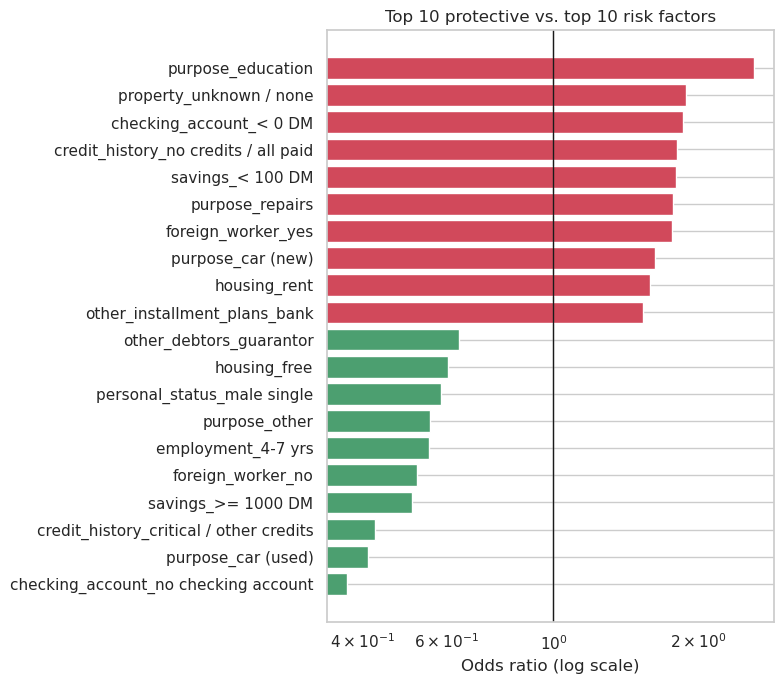

In [16]:
lr = pipes["Logistic Regression (balanced)"]
names = lr.named_steps["prep"].get_feature_names_out()
or_ = pd.Series(np.exp(lr.named_steps["clf"].coef_[0]), index=names).sort_values()
or_.index = [i.replace("num__","").replace("cat__","") for i in or_.index]
top = pd.concat([or_.head(10), or_.tail(10)])

plt.figure(figsize=(8,7))
colors = ["#4C9F70" if v < 1 else "#D1495B" for v in top.values]
plt.barh(top.index, top.values, color=colors); plt.axvline(1, color="k", lw=1)
plt.xscale("log"); plt.xlabel("Odds ratio (log scale)"); plt.title("Top 10 protective vs. top 10 risk factors")
plt.tight_layout(); plt.savefig(IMG+"07_odds_en.png", dpi=150); plt.show()

### 8.2 Permutation importance (best model, test set)
Model-agnostic: how much does ROC-AUC drop when one original feature is shuffled?

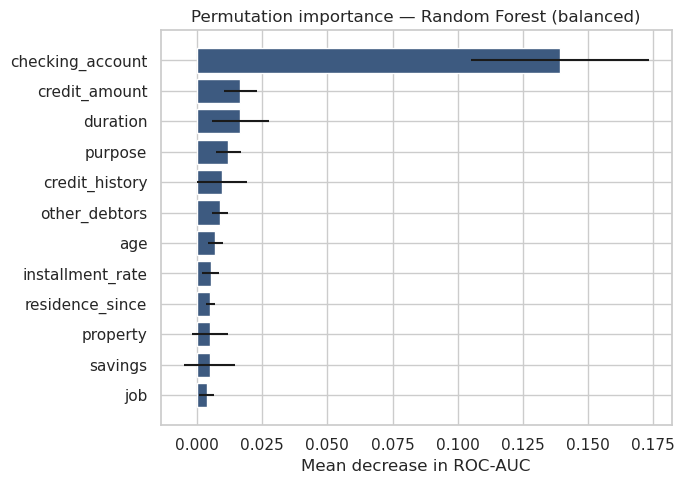

In [17]:
pi = permutation_importance(fitted[best_name], X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values().tail(12)
err = pd.Series(pi.importances_std, index=X_test.columns)[imp.index]

plt.figure(figsize=(7,5))
plt.barh(imp.index, imp.values, xerr=err.values, color="#3D5A80")
plt.xlabel("Mean decrease in ROC-AUC"); plt.title("Permutation importance — " + best_name)
plt.tight_layout(); plt.savefig(IMG+"08_perm_en.png", dpi=150); plt.show()

## 9. Conclusions & limitations

**Results**
- **Model quality:** the four models reach a similar ROC-AUC of roughly **0.77–0.81** (cross-validation: Random Forest 0.797, Logistic Regression 0.771; test set: 0.78–0.81). The gaps are within the CV standard deviation (≈ 0.04), so no model is clearly better — a simple, explainable **logistic regression is fully competitive**.
- **Business value:** with the 5:1 cost matrix, moving the threshold from 0.50 to **0.33** cuts the test-set cost from **150 to 94 (−37 %)**, and the recall of bad risks rises from **0.58 to 0.90**. For reference, approving everybody costs 300 and rejecting everybody costs 140.
- **Trade-off:** the price is more false alarms — the model rejects about **46 % of good clients** (vs. 18 % at 0.50). The right threshold is ultimately a business decision.
- **Why 0.33 and not 0.17?** The theoretical threshold 1/6 assumes calibrated probabilities. A `class_weight="balanced"` Random Forest is not calibrated, so the empirical optimum differs.
- **Main drivers:** the checking-account status clearly dominates (permutation importance far above everything else), followed by loan duration, credit amount, purpose and credit history.

**Limitations**
- Only **1,000 rows** (200 in the test set, 60 bad clients): test metrics are noisy and should be read as indicative, not exact. The same code gave a cost of 150 → 94 in one environment and 128 → 100 in another (different library versions), so treat small differences with caution.
- The dataset is from 1994 (Germany, in DM) and has known quirks (e.g. the *critical* credit-history paradox seen in the EDA).
- **Fairness:** `personal_status`, `foreign_worker` and `age` are sensitive attributes. A production scoring model could not legally use them in many jurisdictions; they are kept here only to stay comparable with the original benchmark, as a learning exercise.

**Next steps:** repeated/nested cross-validation, hyper-parameter tuning, probability calibration, SHAP explanations, a fairness audit (with and without sensitive features), and a small Streamlit demo.
